In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("soccer.db")

query = """
SELECT season,
       ROUND(100.0 * SUM(CASE WHEN home_team_goal > away_team_goal THEN 1 ELSE 0 END) / COUNT(*), 1) AS home_win_pct
FROM Match
GROUP BY season
ORDER BY season
"""

df = pd.read_sql(query, conn)
df


,season,home_win_pct
0,2008/2009,47.1
1,2009/2010,47.4
2,2010/2011,46.6
3,2011/2012,46.5
4,2012/2013,44.3
5,2013/2014,46.3
6,2014/2015,44.9
7,2015/2016,43.9


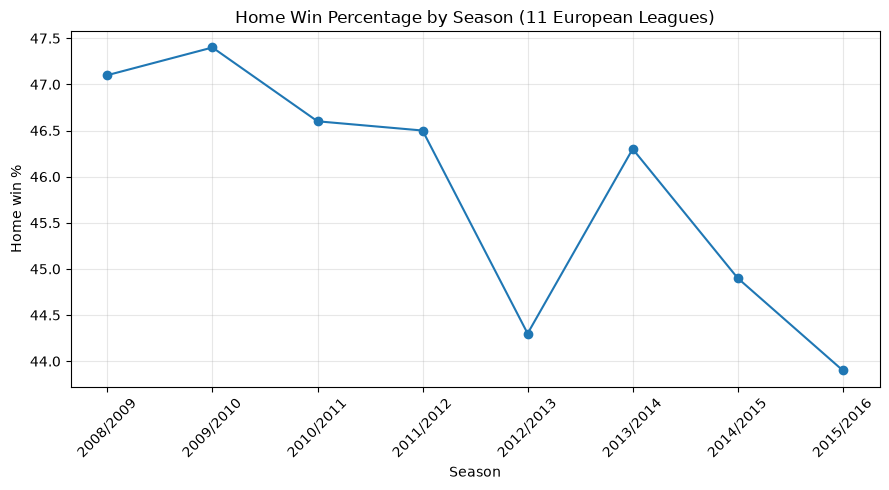

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(df["season"], df["home_win_pct"], marker="o")
plt.title("Home Win Percentage by Season (11 European Leagues)")
plt.xlabel("Season")
plt.ylabel("Home win %")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Home_win_by_season.png", dpi=150)
plt.show()

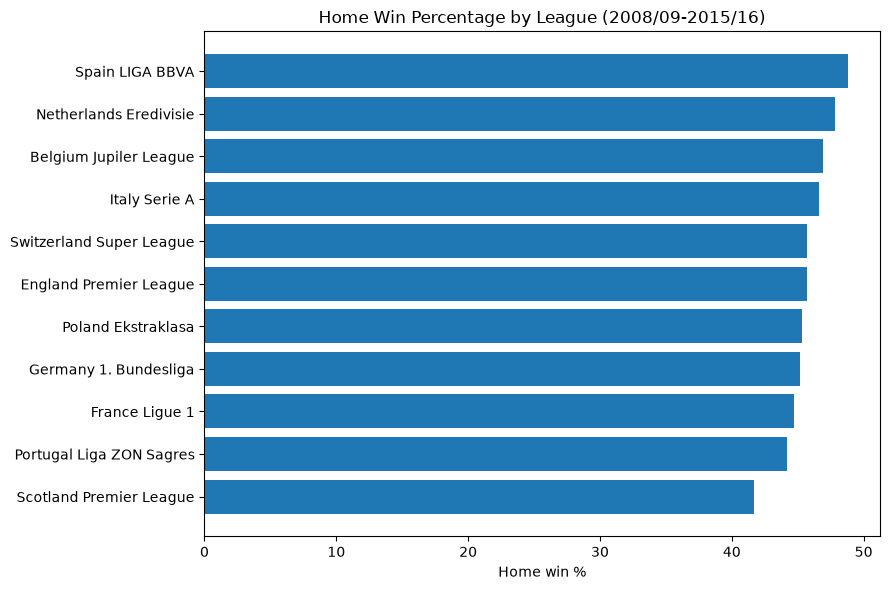

In [4]:
query2 = """
SELECT League.name AS league,
       ROUND(100.0 * SUM(CASE WHEN home_team_goal > away_team_goal THEN 1 ELSE 0 END) / COUNT(*), 1) AS home_win_pct
FROM Match
JOIN League ON Match.league_id = League.id
GROUP BY League.name
ORDER BY home_win_pct
"""

df2 = pd.read_sql(query2, conn)

plt.figure(figsize=(9, 6))
plt.barh(df2["league"], df2["home_win_pct"])
plt.title("Home Win Percentage by League (2008/09-2015/16)")
plt.xlabel("Home win %")
plt.tight_layout()
plt.savefig("home_win_by_league.png", dpi=150)
plt.show()

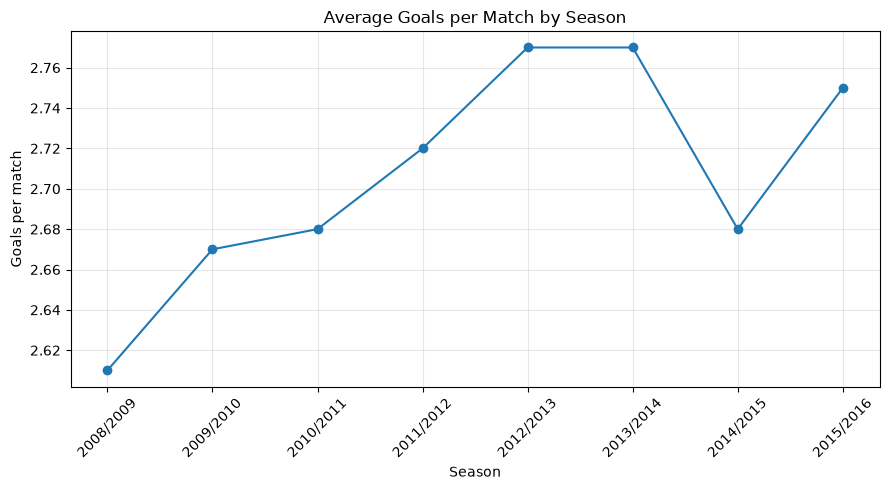

In [3]:
query3 = """
SELECT season, ROUND(AVG(home_team_goal + away_team_goal), 2) AS avg_goals
FROM Match
GROUP BY season
ORDER BY season
"""
df3 = pd.read_sql(query3, conn)

plt.figure(figsize=(9, 5))
plt.plot(df3["season"], df3["avg_goals"], marker="o")
plt.title("Average Goals per Match by Season")
plt.xlabel("Season")
plt.ylabel("Goals per match")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("goals_by_season.png", dpi=150)
plt.show()